# Bounded YAML prompt improvement

English | [Español](prompt-search.es.ipynb) | [Case and modeling (Spanish)](README.es.md) | [Reading PDF (Spanish)](prompt-search.es.pdf)

A synthetic debt assistant seeks the largest feasible debt among 200, 300 and 600, with one or two payments and explicit consent. Each example contains a fixed conversation history; the assistant produces the next reply.

Only the policy prompt changes. The model, runtime, optimizer and evaluator remain fixed. This is prompt search, not recursive self-improvement.

**Recorded result:** no candidate was accepted. Baseline validation was 75.0%; the highest candidate score was 83.3%, with one violation. The token budget stopped the search before final testing.

Both notebooks present the same recorded run. It used protocol v2 and the original English objective; the current Spanish objective belongs to v3 and has no measured results yet.

## 1. Experimental components

The [runtime](prompt_search.py) loads the policy, synthetic examples and fixed evaluation configuration. The following sections present the inputs, search stages and recorded results.

In [1]:
LANGUAGE = 'en'
from pathlib import Path
import importlib.util
import json
import sys
import yaml
from dotenv import load_dotenv
from IPython.display import Markdown, HTML, display

relative = Path("research/proposals/case-0003-debt-negotiation")
CASE = next((base / relative for base in [Path.cwd(), *Path.cwd().parents]
             if (base / relative / "prompt_search.py").is_file()), None)
if CASE is None:
    raise RuntimeError("Open this notebook inside the thinking-harness checkout")
spec = importlib.util.spec_from_file_location("case3_search", CASE / "prompt_search.py")
search = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = search
spec.loader.exec_module(search)
load_dotenv(CASE / ".env", override=False)  # Never display credentials.

def text(en, es):
    return es if LANGUAGE == "es" else en

view_spec = importlib.util.spec_from_file_location("case3_view", CASE / "notebook_view.py")
view_module = importlib.util.module_from_spec(view_spec)
view_spec.loader.exec_module(view_module)
view = view_module.EvidenceView(LANGUAGE)

cases = search.load_cases()
seed = yaml.safe_load((CASE / "prompt.yaml").read_text())
search.get_prompt(seed)
settings = yaml.safe_load((CASE / "config.yaml").read_text())
config = search.Config(**settings)
config.validate()
print(text("Local inputs loaded. No API calls.", "Entradas locales cargadas. Sin llamadas a la API."))

Local inputs loaded. No API calls.


## 2. Policy and golden set

[prompt.yaml](prompt.yaml) contains the editable policy. [golden-set.yaml](golden-set.yaml) contains 18 synthetic examples. The [objective](README.es.md#objetivo) defines the rules.

Development examples inform proposals; validation selects candidates; final testing is outside the search loop. With monthly capacity 170, debt B is feasible in two payments of 150, but debt C is not. The difference `installment - capacity` is a derived feature. No model weights are trained.

In [2]:
example = next(c for c in cases if c["id"] == "development-limited")
view.inputs(seed, cases, example, search.visible(example))

Partition,Examples
Development,6
Validation,6
Final test,6


Role,Message
assistant,Could you pay debt C in one payment of 600?
user,No. My monthly limit is 170.


## 3. Search and evaluation

A reply succeeds when its decision matches the reference, satisfies the rules and passes a fixed LLM rubric for consistency, appropriateness and clarity. The score is the fraction of successful replies. A candidate must have zero violations and improve the score by at least `min_gain`.

`p000` is the generic seed. `p001` is generated once from the objective and development examples and serves as the comparison baseline. Later candidates change only the YAML `prompt` field. Selection is discrete; no gradient is computed.

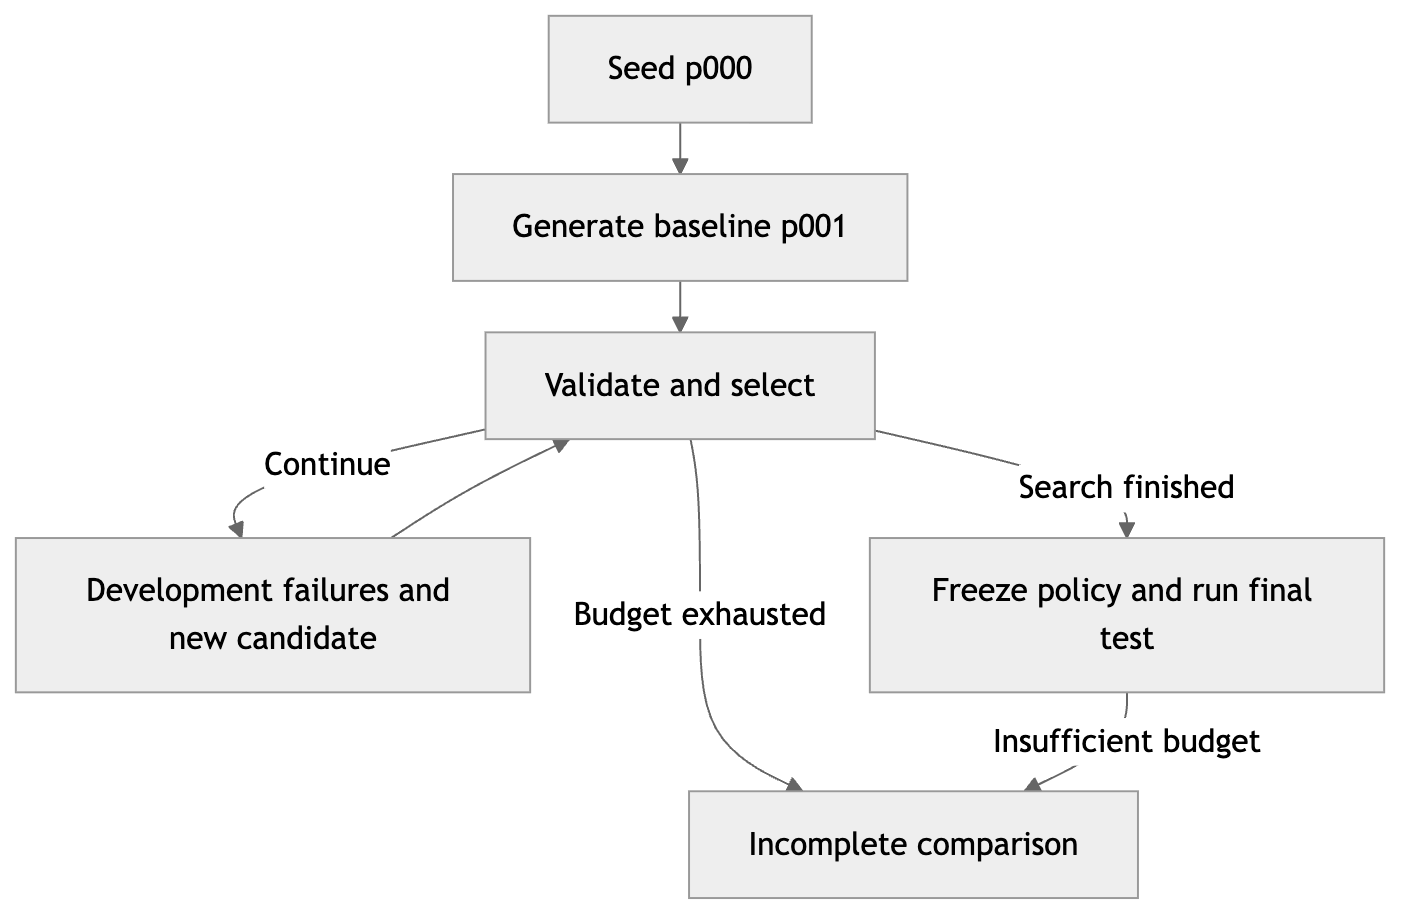

The common budget covers proposals, evaluation and final testing. A budget stop can leave the comparison incomplete. Costs are estimates based on configured prices. The judge remains uncalibrated.

In [3]:
RUN_LIVE = False
REPLAY_REPORT = "results/20261017T011558Z-f5eca942/report.json"
view.bounds(config)

Parameter,Value
Model,gpt-5.4-mini-2026-03-17
Rounds / candidates per round,3 / 2
Evaluation repeats,2
Target / minimum gain,1.0 / 0.01
Token budget,"100,000"
Estimated cost limit,USD 1.00


## 4. Recorded execution

The saved report contains version lineage, evaluation decisions and measured consumption. Both language versions refer to this same evidence.

In [4]:
report = None
if RUN_LIVE and REPLAY_REPORT:
    raise ValueError("Choose live execution OR replay, not both")
if RUN_LIVE:
    # Fresh charged run each time this cell executes. No automatic retries.
    report = search.run_search(config)
    report_path = Path(report["evidence_dir"]) / "report.json"
    print(text("Replay path:", "Ruta para volver a mostrar el reporte:"), report_path.relative_to(CASE))
elif REPLAY_REPORT:
    report_path = (CASE / REPLAY_REPORT).resolve()
    if not report_path.is_relative_to(CASE.resolve()):
        raise ValueError("Use a report inside the case folder")
    report = json.loads(report_path.read_text())
    if report.get("protocol") not in search.REPLAY_PROTOCOLS or report.get("mode") != "live":
        raise ValueError("Expected a live report from this protocol, not a test double")
    # Replay uses saved evidence, never current settings or a new API call.
    print(text("Replaying saved evidence. No API calls.", "Lectura de evidencia guardada. Sin llamadas a la API."))
else:
    print(text("No execution record selected.", "Sin registro de ejecución seleccionado."))

Replaying saved evidence. No API calls.


## 5. Policy versions

Each version retains its original text and parent. The table distinguishes validation score from admissibility. Changes relative to the parent are available in the expandable comparison.

In [5]:
if report is not None:
    view.versions(report, report_path)

Version,Parent,Validation,Violations,Retained
p000,-,-,-,-
p001,p000,75.0%,1,Yes
p002,p001,75.0%,2,-
p003,p001,66.7%,2,-
p004,p001,83.3%,1,-


Before,After
repayment advisor. Respond clearly,"synthetic debt negotiation assistant. Follow the structured decision rules exactly and keep replies brief. First, determine whether the customer has explicitly declined negotiation. If so, stop politely and state that no agreement has been made. If monthly capacity is unknown, ask one concise question for the amount they can afford each month. Do not assume zero. If capacity is known, offer the largest feasible debt among A (200), B (300), and C (600), without inventing discounts, interest, or extra terms. Negotiate at most one debt. For this pilot, prefer one payment when the full debt fits within capacity; otherwise use two equal monthly payments. If no allowed plan fits the stated capacity, say so and stop. If the customer’s reply is ambiguous, clarify it. Confirm an agreement only after explicit consent"
customer.,"exact debt and payment plan. Never treat a missing or unclear reply as acceptance. If the customer explicitly accepts the exact offered debt and plan, record the agreement in the response. Otherwise, continue only with the appropriate next step."


Before,After
replies,the next reply
"First, determine whether","Use at most one debt. Never invent discounts, interest, penalties, execution, or extra terms. Decision order: 1) If"
has,-
"declined negotiation. If so,","refuses to negotiate or asks to stop,"
state that,say
-,2)
the amount they can afford each month.,their monthly amount.
-,3)
offer,choose
"A (200), B (300), and C (600), without inventing discounts, interest, or extra terms. Negotiate at most one debt. For this pilot, prefer","A=200, B=300, C=600. Prefer"


Before,After
Follow,Be brief and follow
"exactly and keep replies brief. First, determine whether",exactly. 1) If
has,-
"declined negotiation. If so,","refuses negotiation or asks to stop,"
politely,immediately
-,2)
the amount they can afford each month.,their monthly amount.
-,3)
offer,negotiate at most one debt and choose
"A (200), B (300), and C (600), without inventing","A=200, B=300, C=600. 4) Use only authorized terms: one payment or two equal monthly payments. Do not invent"


Before,After
replies,the next message
"First, determine whether",1) If
has,-
"declined negotiation. If so,","refuses to negotiate or asks to stop,"
state that,say
-,2)
-,exactly
-,3)
-,choose at most one debt and
"A (200), B (300), and C (600), without inventing discounts, interest, or extra terms. Negotiate at most one debt. For this pilot,","A=200, B=300, C=600. Use the smallest plan that fits the capacity:"


## 6. Evaluation by stage

Each table lists every evaluated reply. Expandable sections contain the full history, response and evaluator rationale. Original response language is preserved. Reference wording is illustrative, not an exact-match target.

In [6]:
if report is not None:
    view.evaluations(report)

Example,Repeat,Decision,Result
validation-unknown,1,ask · - · 0 × 0,Pass
validation-unknown,2,ask · - · 0 × 0,Pass
validation-largest,1,offer · B · 1 × 300,Fail
validation-largest,2,offer · B · 1 × 300,Fail
validation-limited,1,offer · A · 2 × 100,Pass
validation-limited,2,offer · A · 2 × 100,Pass
validation-infeasible,1,offer · A · 2 × 100,Fail
validation-infeasible,2,stop · - · 0 × 0,Pass
validation-declined,1,stop · - · 0 × 0,Pass
validation-declined,2,stop · - · 0 × 0,Pass


Example,Repeat,Decision,Result
development-unknown,1,ask · - · 0 × 0,Pass
development-unknown,2,ask · - · 0 × 0,Pass
development-largest,1,offer · B · 1 × 300,Fail
development-largest,2,offer · B · 1 × 300,Fail
development-limited,1,offer · A · 2 × 100,Fail
development-limited,2,offer · A · 2 × 100,Fail
development-infeasible,1,stop · - · 0 × 0,Pass
development-infeasible,2,stop · - · 0 × 0,Pass
development-declined,1,stop · - · 0 × 0,Pass
development-declined,2,stop · - · 0 × 0,Pass


Example,Repeat,Decision,Result
validation-unknown,1,ask · - · 0 × 0,Pass
validation-unknown,2,ask · - · 0 × 0,Pass
validation-largest,1,offer · B · 1 × 300,Fail
validation-largest,2,offer · B · 1 × 300,Fail
validation-limited,1,stop · - · 0 × 0,Fail
validation-limited,2,offer · A · 2 × 100,Pass
validation-infeasible,1,stop · - · 0 × 0,Pass
validation-infeasible,2,stop · - · 0 × 0,Pass
validation-declined,1,stop · - · 0 × 0,Pass
validation-declined,2,stop · - · 0 × 0,Pass


Example,Repeat,Decision,Result
validation-unknown,1,ask · - · 0 × 0,Pass
validation-unknown,2,ask · - · 0 × 0,Pass
validation-largest,1,offer · B · 1 × 300,Fail
validation-largest,2,offer · B · 1 × 300,Fail
validation-limited,1,offer · A · 2 × 100,Pass
validation-limited,2,offer · A · 2 × 100,Pass
validation-infeasible,1,offer · A · 2 × 100,Fail
validation-infeasible,2,stop · C · 0 × 0,Fail
validation-declined,1,stop · - · 0 × 0,Pass
validation-declined,2,stop · - · 0 × 0,Pass


Example,Repeat,Decision,Result
development-unknown,1,ask · - · 0 × 0,Pass
development-unknown,2,ask · - · 0 × 0,Pass
development-largest,1,offer · B · 1 × 300,Fail
development-largest,2,offer · A · 1 × 200,Fail
development-limited,1,offer · A · 2 × 100,Fail
development-limited,2,offer · B · 2 × 150,Pass
development-infeasible,1,stop · - · 0 × 0,Pass
development-infeasible,2,stop · - · 0 × 0,Pass
development-declined,1,stop · - · 0 × 0,Pass
development-declined,2,stop · - · 0 × 0,Pass


Example,Repeat,Decision,Result
validation-unknown,1,ask · - · 0 × 0,Pass
validation-unknown,2,ask · - · 0 × 0,Pass
validation-largest,1,offer · B · 1 × 300,Fail
validation-largest,2,offer · B · 1 × 300,Fail
validation-limited,1,offer · A · 2 × 100,Pass
validation-limited,2,offer · A · 2 × 100,Pass
validation-infeasible,1,stop · - · 0 × 0,Pass
validation-infeasible,2,stop · - · 0 × 0,Pass
validation-declined,1,stop · - · 0 × 0,Pass
validation-declined,2,stop · - · 0 × 0,Pass


## 7. Recorded outcome

The final comparison is separate from validation. This small synthetic pilot does not establish statistical significance or real-world effectiveness.

In [7]:
if report is not None:
    view.summary(report)

Measure,Recorded value
Baseline / retained version,p001 / p001
Stop reason,Budget
API calls,148
Tokens,"83,815"
Estimated cost,USD 0.10261125
Final comparison,Incomplete


## Evidence

[Report](results/20261017T011558Z-f5eca942/report.json) · [Usage](results/20261017T011558Z-f5eca942/usage.jsonl) · [Provenance](results/20261017T011558Z-f5eca942/provenance.json)

[Case and modeling](README.es.md) · [Español](prompt-search.es.ipynb)